# KTAS Triage Prediction - Improved Pipeline
**Target:** `KTAS_expert` (1-5)

**Isme kya naya hai (pehle wale version se):**
1. `Chief_complain` (symptom) ab use ho raha hai
2. Medical features: pulse pressure, shock index, MAP
3. Imbalance handling (`class_weight="balanced"`)
4. Hyperparameter tuning (Random Forest, Gradient Boosting, SVM, Logistic Regression)
5. Soft-voting **Ensemble**
6. Medical metrics: Macro F1, Within +-1 level, QWK, Undertriage / Overtriage
7. Cross-validation, feature importance
8. **Prediction function** (naye patient ka KTAS predict karo) + model save/load

Setup: `pip install -U pandas numpy scikit-learn matplotlib seaborn scipy joblib ipykernel`

## Step 1: Imports

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib

from scipy.stats import randint, loguniform
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, VotingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score,
                             classification_report, confusion_matrix)
RANDOM_STATE = 42

## Step 2: Load dataset
Delimiter `;` aur encoding `cp1252`. **`CSV_PATH` apni file ke path se badlo.**

In [2]:
CSV_PATH =r"C:\Users\shris\Downloads\data.csv"   # e.g. r"C:\Users\you\Downloads\data.csv"

try:
    df = pd.read_csv(CSV_PATH, sep=";", encoding="cp1252")
except UnicodeDecodeError:
    df = pd.read_csv(CSV_PATH, sep=";", encoding="utf-8", encoding_errors="ignore")

print("Shape:", df.shape)
df.head()

Shape: (1267, 24)


,Group,Sex,Age,Patients number per hour,Arrival mode,Injury,Chief_complain,Mental,Pain,NRS_pain,...,BT,Saturation,KTAS_RN,Diagnosis in ED,Disposition,KTAS_expert,Error_group,Length of stay_min,KTAS duration_min,mistriage
0,2,2,71,3,3,2,right ocular pain,1,1,2,...,36.6,100,2,Corneal abrasion,1,4,2,86,"5,00",1
1,1,1,56,12,3,2,right forearm burn,1,1,2,...,36.5,NaN,4,"Burn of hand, firts degree dorsum",1,5,4,64,"3,95",1
2,2,1,68,8,2,2,"arm pain, Lt",1,1,2,...,36.6,98,4,"Fracture of surgical neck of humerus, closed",2,5,4,862,"1,00",1
3,1,2,71,8,1,1,ascites tapping,1,1,3,...,36.5,NaN,4,Alcoholic liver cirrhosis with ascites,1,5,6,108,"9,83",1
4,1,2,58,4,3,1,"distension, abd",1,1,3,...,36.5,NaN,4,Ascites,1,5,8,109,"6,60",1


## Step 3: Data samjho

KTAS_expert
1     26
2    220
3    487
4    459
5     75
Name: count, dtype: int64


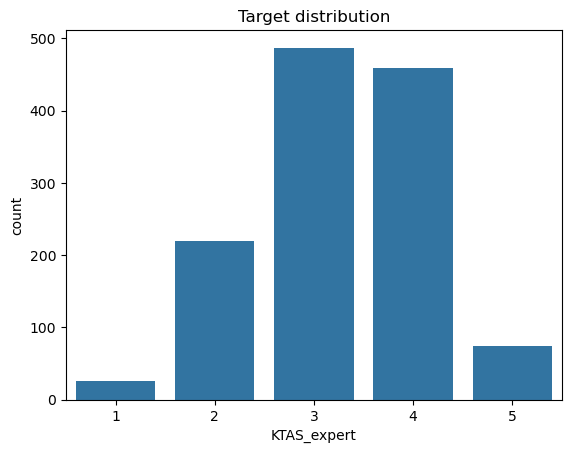

Saturation         688
Diagnosis in ED      2
dtype: int64


In [3]:
print(df["KTAS_expert"].value_counts().sort_index())
sns.countplot(x="KTAS_expert", data=df); plt.title("Target distribution"); plt.show()
print(df.isnull().sum()[df.isnull().sum() > 0])

## Step 4: Feature engineering (cleaning + naye medical features)

- `??` / comma-decimals handle
- `NRS_pain`: agar `Pain == 0` to pain score 0
- Leakage wale columns (`KTAS_RN`, `Diagnosis in ED`, `Disposition`, `Error_group`, `mistriage`, `Length of stay_min`, `KTAS duration_min`) **use nahi kiye**
- Naye features: **pulse pressure** (SBP-DBP), **shock index** (HR/SBP), **MAP** ((SBP+2*DBP)/3)

Yahi `add_features` function baad mein prediction ke time bhi use hota hai.

In [4]:
RAW_NUM = [c for c in ["Age","Patients number per hour","Mental","NRS_pain","SBP","DBP","HR","RR","BT","Saturation"] if c in df.columns]
RAW_CAT = [c for c in ["Group","Sex","Arrival mode","Injury","Pain","Chief_complain"] if c in df.columns]
ALL_RAW = RAW_NUM + RAW_CAT

NUM_FEATS = RAW_NUM + ["pulse_pressure", "shock_index", "MAP"]
CAT_FEATS = RAW_CAT
FEATURES  = NUM_FEATS + CAT_FEATS

def add_features(data):
    d = data.copy().reindex(columns=ALL_RAW)
    d = d.replace("??", np.nan)
    pain_zero = pd.to_numeric(d["Pain"], errors="coerce") == 0 if "Pain" in d else pd.Series(False, index=d.index)
    for c in RAW_NUM:
        d[c] = pd.to_numeric(d[c].astype(str).str.replace(",", ".", regex=False), errors="coerce")
    if "NRS_pain" in d:
        d.loc[pain_zero, "NRS_pain"] = 0
    for c in RAW_CAT:
        d[c] = d[c].astype(str).str.strip().str.lower()
    d["pulse_pressure"] = d["SBP"] - d["DBP"]
    d["shock_index"]    = d["HR"] / d["SBP"].replace(0, np.nan)
    d["MAP"]            = (d["SBP"] + 2 * d["DBP"]) / 3
    d = d.replace([np.inf, -np.inf], np.nan)
    return d[FEATURES]

df = df.dropna(subset=["KTAS_expert"])
X = add_features(df)
y = df["KTAS_expert"].astype(int)
print(X.shape, "| Chief_complain unique:", X["Chief_complain"].nunique() if "Chief_complain" in X else "NA")
X.head()

(1267, 19) | Chief_complain unique: 412


,Age,Patients number per hour,Mental,NRS_pain,SBP,DBP,HR,RR,BT,Saturation,pulse_pressure,shock_index,MAP,Group,Sex,Arrival mode,Injury,Pain,Chief_complain
0,71,3,1,2.0,160.0,100.0,84.0,18.0,36.6,100.0,60.0,0.525000,120.000000,2,2,3,2,1,right ocular pain
1,56,12,1,2.0,137.0,75.0,60.0,20.0,36.5,NaN,62.0,0.437956,95.666667,1,1,3,2,1,right forearm burn
2,68,8,1,2.0,130.0,80.0,102.0,20.0,36.6,98.0,50.0,0.784615,96.666667,2,1,2,2,1,"arm pain, lt"
3,71,8,1,3.0,139.0,94.0,88.0,20.0,36.5,NaN,45.0,0.633094,109.000000,1,2,1,1,1,ascites tapping
4,58,4,1,3.0,91.0,67.0,93.0,18.0,36.5,NaN,24.0,1.021978,75.000000,1,2,3,1,1,"distension, abd"


## Step 5: Train/test split + preprocessing
Preprocessing pipeline ke andar hai, isliye cross-validation mein leakage nahi hoti. Rare `Chief_complain` categories (15 se kam) automatically "infrequent" group mein jaati hain.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

TEXT_COL = "Chief_complain"
CAT_ONLY = [c for c in CAT_FEATS if c != TEXT_COL]

num_pipe = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                     ("sc", StandardScaler())])
cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                     ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
txt_pipe = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=150)

prep = ColumnTransformer([("num", num_pipe, NUM_FEATS),
                          ("cat", cat_pipe, CAT_ONLY),
                          ("txt", txt_pipe, TEXT_COL)], sparse_threshold=0)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1013, 19) Test: (254, 19)


## Step 6: Baseline models (pehle wale 4 models, naye features ke saath)

In [6]:
def make(clf): return Pipeline([("prep", clone(prep)), ("clf", clf)])

baselines = {
    "KNN (base)":           make(KNeighborsClassifier(n_neighbors=5)),
    "Naive Bayes (base)":   make(GaussianNB()),
    "Decision Tree (base)": make(DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE)),
    "SVM (base)":           make(SVC(kernel="rbf", random_state=RANDOM_STATE)),
}
for n, m in baselines.items():
    m.fit(X_train, y_train)
    print(f"{n}: acc = {accuracy_score(y_test, m.predict(X_test)):.4f}")

  File "c:\Users\shris\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\shris\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\shris\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\shris\anaconda3\Lib\subprocess.

KNN (base): acc = 0.5472
Naive Bayes (base): acc = 0.2441
Decision Tree (base): acc = 0.6969
SVM (base): acc = 0.6654


## Step 7: Hyperparameter tuning (imbalance handle ke saath)
Scoring `f1_macro` hai taaki rare classes ko bhi barabar importance mile. Thoda time lag sakta hai (kuch minute).

In [7]:
searches = {
  "Random Forest": (RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1),
      {"clf__n_estimators": randint(200, 500), "clf__max_depth": [None, 6, 10, 15],
       "clf__min_samples_leaf": randint(1, 8), "clf__max_features": ["sqrt", "log2", 0.5]}),
  "Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
      {"clf__learning_rate": loguniform(0.02, 0.2), "clf__max_iter": randint(100, 300),
       "clf__max_leaf_nodes": randint(8, 40), "clf__min_samples_leaf": randint(10, 50),
       "clf__l2_regularization": loguniform(1e-3, 10)}),
  "SVM": (SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE),
      {"clf__C": loguniform(0.3, 30), "clf__gamma": loguniform(1e-3, 0.3)}),
  "Logistic Regression": (LogisticRegression(class_weight="balanced", max_iter=3000),
      {"clf__C": loguniform(0.01, 10)}),
}

skf3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
tuned = {}
for name, (clf, params) in searches.items():
    rs = RandomizedSearchCV(make(clf), params, n_iter=12, cv=skf3, scoring="f1_macro",
                            random_state=RANDOM_STATE, n_jobs=-1)
    rs.fit(X_train, y_train)
    tuned[name + " (tuned)"] = rs.best_estimator_
    print(f"{name}: CV macro-F1 = {rs.best_score_:.4f}")
    print("   best params:", {k.replace('clf__',''): (round(float(v),4) if isinstance(v,(float,np.floating)) else v) for k, v in rs.best_params_.items()})

Random Forest: CV macro-F1 = 0.5432
   best params: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 221}
Gradient Boosting: CV macro-F1 = 0.5106
   best params: {'l2_regularization': 1.0506, 'learning_rate': 0.0532, 'max_iter': 153, 'max_leaf_nodes': 17, 'min_samples_leaf': 13}
SVM: CV macro-F1 = 0.5206
   best params: {'C': 8.7319, 'gamma': 0.0304}
Logistic Regression: CV macro-F1 = 0.5550
   best params: {'C': 8.1232}


## Step 8: Ensemble (Soft Voting)
Teen tuned models (RF + Gradient Boosting + SVM) ki probabilities ka average.

In [8]:
# tuned SVM ko probability support ke saath refit (prediction mein probabilities dikhane ke liye)
tuned["SVM (tuned)"] = clone(tuned["SVM (tuned)"]).set_params(clf__probability=True).fit(X_train, y_train)

def tuned_clf(name):
    c = clone(tuned[name].named_steps["clf"])
    if isinstance(c, SVC): c.set_params(probability=True)
    return c

ensemble = make(VotingClassifier(
    [("rf", tuned_clf("Random Forest (tuned)")),
     ("gb", tuned_clf("Gradient Boosting (tuned)")),
     ("svm", tuned_clf("SVM (tuned)"))], voting="soft"))
ensemble.fit(X_train, y_train)

all_models = {**baselines, **tuned, "Ensemble (RF+GB+SVM)": ensemble}
print("Models ready:", list(all_models))

Models ready: ['KNN (base)', 'Naive Bayes (base)', 'Decision Tree (base)', 'SVM (base)', 'Random Forest (tuned)', 'Gradient Boosting (tuned)', 'SVM (tuned)', 'Logistic Regression (tuned)', 'Ensemble (RF+GB+SVM)']


## Step 9: Evaluation - medical metrics

- **Within +-1:** prediction sahi level ya padosi level ke andar
- **QWK:** Quadratic Weighted Kappa (ordinal labels ke liye, door ki galti ko zyada penalty)
- **Undertriage:** model ne patient ko *kam urgent* bola (khatarnak galti)
- **Overtriage:** model ne *zyada urgent* bola

In [9]:
BEST_BY = "Macro F1"      # chaho to "Accuracy" ya "QWK" kar sakte ho

def evaluate(model):
    p = model.predict(X_test)
    diff = p - y_test.values
    return {"Accuracy": accuracy_score(y_test, p),
            "Macro F1": f1_score(y_test, p, average="macro"),
            "Within +-1": (np.abs(diff) <= 1).mean(),
            "QWK": cohen_kappa_score(y_test, p, weights="quadratic"),
            "Undertriage": (diff > 0).mean(),
            "Overtriage": (diff < 0).mean()}

metrics_df = pd.DataFrame({n: evaluate(m) for n, m in all_models.items()}).T.round(4)
metrics_df = metrics_df.sort_values(BEST_BY, ascending=False)
display(metrics_df)

best_name = metrics_df.index[0]
best_model = all_models[best_name]
print(f"\nBEST MODEL (by {BEST_BY}): {best_name}")

,Accuracy,Macro F1,Within +-1,QWK,Undertriage,Overtriage
Logistic Regression (tuned),0.6457,0.6193,0.9291,0.6210,0.1693,0.1850
Gradient Boosting (tuned),0.6535,0.6087,0.9094,0.5704,0.1772,0.1693
SVM (tuned),0.6417,0.5786,0.8937,0.5108,0.1614,0.1969
Random Forest (tuned),0.7008,0.5741,0.9331,0.5857,0.1457,0.1535
Decision Tree (base),0.6969,0.5664,0.9173,0.5709,0.1299,0.1732
Ensemble (RF+GB+SVM),0.6929,0.5638,0.9173,0.5483,0.1457,0.1614
SVM (base),0.6654,0.5326,0.9055,0.4804,0.1732,0.1614
KNN (base),0.5472,0.4577,0.8819,0.3772,0.2165,0.2362
Naive Bayes (base),0.2441,0.2236,0.5866,0.2073,0.2008,0.5551



BEST MODEL (by Macro F1): Logistic Regression (tuned)


## Step 10: Best model ka detailed report + confusion matrix (labels 1-5)

              precision    recall  f1-score   support

           1       0.67      0.80      0.73         5
           2       0.56      0.70      0.63        44
           3       0.70      0.57      0.63        98
           4       0.71      0.72      0.71        92
           5       0.35      0.47      0.40        15

    accuracy                           0.65       254
   macro avg       0.60      0.65      0.62       254
weighted avg       0.66      0.65      0.65       254



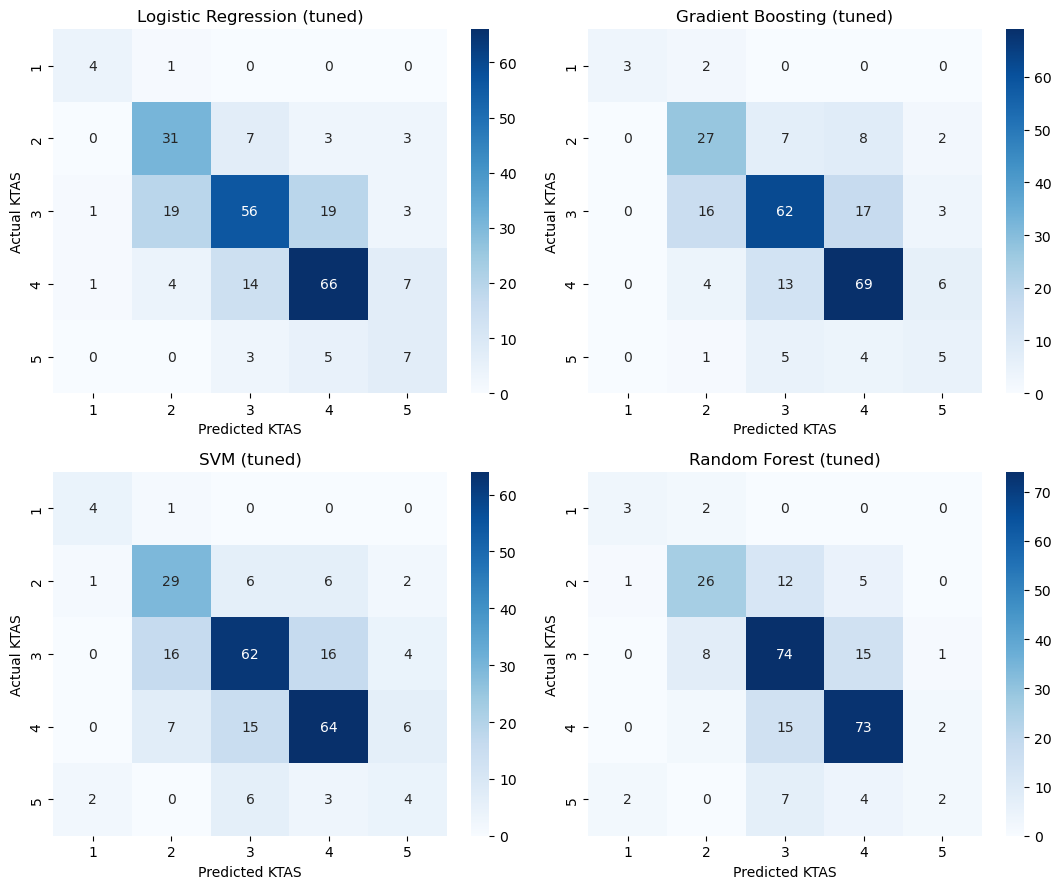

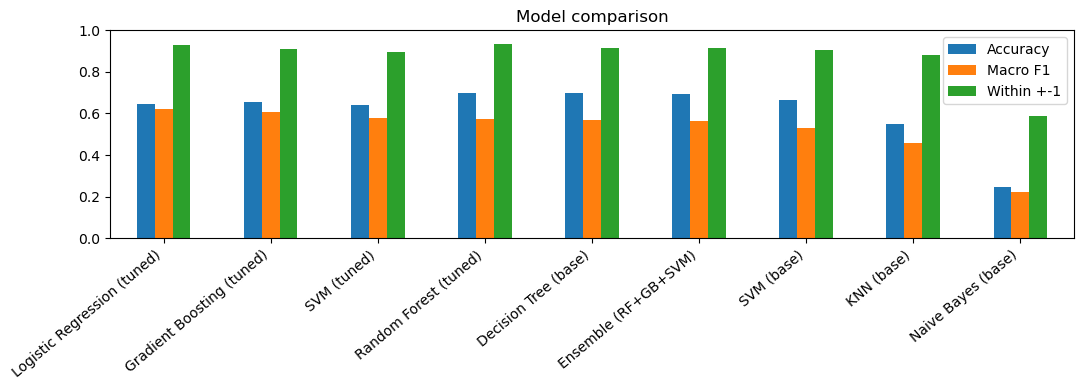

In [10]:
labels = [1, 2, 3, 4, 5]
p_best = best_model.predict(X_test)
print(classification_report(y_test, p_best, labels=labels, zero_division=0))

top4 = metrics_df.index[:4]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, n in zip(axes.ravel(), top4):
    cm = confusion_matrix(y_test, all_models[n].predict(X_test), labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, xticklabels=labels, yticklabels=labels)
    ax.set_title(n); ax.set_xlabel("Predicted KTAS"); ax.set_ylabel("Actual KTAS")
plt.tight_layout(); plt.show()

metrics_df[["Accuracy", "Macro F1", "Within +-1"]].plot(kind="bar", figsize=(11, 4), ylim=(0, 1))
plt.title("Model comparison"); plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

## Step 11: Cross-validation (top 3 models, 5-fold)
Ek hi split pe depend na karke zyada reliable score.

In [11]:
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = {}
for n in metrics_df.index[:3]:
    cv = cross_validate(clone(all_models[n]), X, y, cv=skf5,
                        scoring=["accuracy", "f1_macro"], n_jobs=-1)
    rows[n] = {"CV Accuracy": f"{cv['test_accuracy'].mean():.3f} +- {cv['test_accuracy'].std():.3f}",
               "CV Macro F1": f"{cv['test_f1_macro'].mean():.3f} +- {cv['test_f1_macro'].std():.3f}"}
pd.DataFrame(rows).T

,CV Accuracy,CV Macro F1
Logistic Regression (tuned),0.624 +- 0.014,0.568 +- 0.043
Gradient Boosting (tuned),0.639 +- 0.028,0.551 +- 0.064
SVM (tuned),0.635 +- 0.016,0.593 +- 0.033


## Step 12: Feature importance (best model)
Kaunsa feature prediction mein sabse zyada kaam aaya.

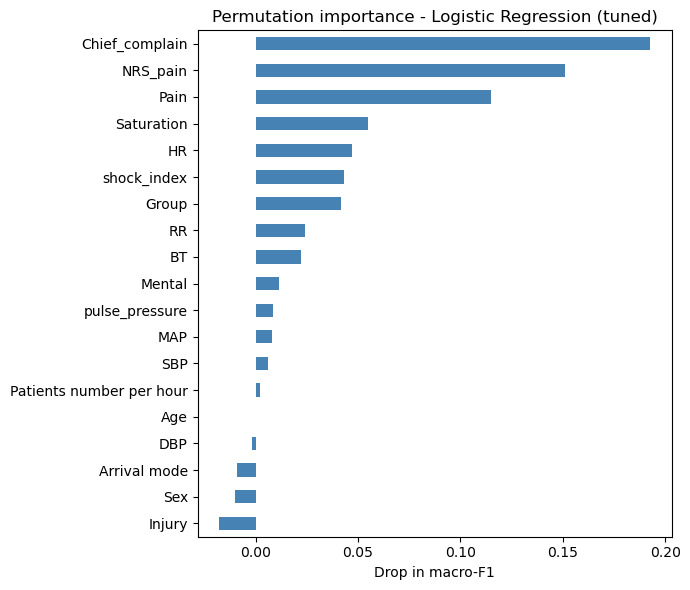

In [12]:
pi = permutation_importance(best_model, X_test, y_test, scoring="f1_macro",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.plot(kind="barh", figsize=(7, 6), color="steelblue")
plt.title(f"Permutation importance - {best_name}"); plt.xlabel("Drop in macro-F1"); plt.tight_layout(); plt.show()

# PREDICTION
## Step 13: Naye patient ka KTAS predict karo

In [13]:
KTAS_MEANING = {1: "Resuscitation (immediate)", 2: "Emergent", 3: "Urgent",
                4: "Less urgent", 5: "Non-urgent"}

def predict_ktas(patient, model=None):
    """patient: dict with raw fields. Missing fields allowed (auto-filled)."""
    model = model or best_model
    X_new = add_features(pd.DataFrame([patient]))
    pred = int(model.predict(X_new)[0])
    print(f"Predicted KTAS: {pred}  ->  {KTAS_MEANING.get(pred, '')}")
    try:
        probs = pd.Series(model.predict_proba(X_new)[0], index=model.classes_).round(3)
        print("Probabilities:", probs.to_dict())
        return pred, probs
    except Exception:
        return pred, None

# ---- Example patient (values apne hisaab se badlo) ----
new_patient = {
    "Group": 2, "Sex": 1, "Age": 65, "Patients number per hour": 5,
    "Arrival mode": 3, "Injury": 1, "Chief_complain": "chest pain",
    "Mental": 1, "Pain": 1, "NRS_pain": 7,
    "SBP": 150, "DBP": 90, "HR": 110, "RR": 22, "BT": 36.8, "Saturation": 95,
}
_ = predict_ktas(new_patient)

Predicted KTAS: 2  ->  Emergent
Probabilities: {1: 0.0, 2: 0.947, 3: 0.052, 4: 0.001, 5: 0.0}


### Test set ke kuch patients: actual vs predicted

In [14]:
sample = X_test.sample(10, random_state=1)
out = sample[["Age", "SBP", "DBP", "HR", "RR", "Saturation"]].copy()
out["Actual KTAS"]    = y_test.loc[sample.index].values
out["Predicted KTAS"] = best_model.predict(sample)
out["Match"] = out["Actual KTAS"] == out["Predicted KTAS"]
out

,Age,SBP,DBP,HR,RR,Saturation,Actual KTAS,Predicted KTAS,Match
785,77,135.0,81.0,73.0,22.0,NaN,5,3,False
180,43,NaN,NaN,NaN,NaN,NaN,2,5,False
957,49,140.0,90.0,64.0,22.0,99.0,3,4,False
1177,81,180.0,100.0,90.0,20.0,99.0,2,2,True
624,54,194.0,84.0,112.0,20.0,NaN,4,4,True
227,59,120.0,76.0,100.0,20.0,NaN,4,2,False
134,92,150.0,90.0,110.0,26.0,88.0,2,3,False
501,47,93.0,55.0,78.0,18.0,NaN,4,4,True
1209,96,90.0,60.0,68.0,20.0,91.0,2,2,True
1266,87,150.0,80.0,62.0,20.0,98.0,3,2,False


### Poore test set ki predictions CSV mein save karo

In [15]:
res = X_test.copy()
res["Actual_KTAS"] = y_test.values
res["Predicted_KTAS"] = best_model.predict(X_test)
res.to_csv("ktas_test_predictions.csv", index=False)
print("Saved: ktas_test_predictions.csv")

Saved: ktas_test_predictions.csv


### Kisi nayi CSV file ke saare patients ka batch prediction

In [16]:
def predict_csv(path_in, path_out="ktas_new_predictions.csv", model=None):
    model = model or best_model
    new = pd.read_csv(path_in, sep=";", encoding="cp1252")
    pred = model.predict(add_features(new))
    new["Predicted_KTAS"] = pred
    new.to_csv(path_out, index=False)
    print(f"Saved {len(new)} predictions -> {path_out}")
    return new

# predict_csv("new_patients.csv")   # uncomment karke apni file ka naam do

## Step 14: Model save / load
Save kiya hua model baad mein bina dobara train kiye use ho sakta hai (load karte waqt `add_features` function aur `FEATURES` list wahan bhi define honi chahiye - isi notebook mein use karna sabse aasan hai).

In [17]:
joblib.dump(best_model, "ktas_best_model.joblib")
print("Saved: ktas_best_model.joblib")

# Baad mein load karne ke liye:
# loaded = joblib.load("ktas_best_model.joblib")
# predict_ktas(new_patient, model=loaded)

Saved: ktas_best_model.joblib
